In [1]:
import os
import pandas as pd
import yaml
import numpy as np
import matplotlib.pyplot as plt
from utils.eval_utils import load_trial_results, generate_summary_table, get_kfold_mean_metrics, plot_learning_curves
import torch
import random
from pytorch_lightning import seed_everything
from dataset.tracking_dataset import load_data_list
from sklearn.model_selection import train_test_split
from train.train_lstm import train_lstm_pipeline

#### Descargar logs

In [2]:
# !lightning download folder logs/bayesian_log/trial_8 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_8
# !lightning download folder logs/bayesian_log/trial_9 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_9
# !lightning download folder logs/bayesian_log/trial_10 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_10
# !lightning download folder logs/bayesian_log/trial_11 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_11
# !lightning download folder logs/bayesian_log/trial_12 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_12
# !lightning download folder logs/bayesian_log/trial_13 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_13
# !lightning download folder logs/bayesian_log/trial_14 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_14
# !lightning download folder logs/bayesian_log/trial_15 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_15
# !lightning download folder logs/bayesian_log/trial_16 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_16

## Optimización de Hiperparámetros

### Resultados de Bayesian Search loss - std

In [3]:
log_directory = '../../logs/bayesian_log'

trials = 20
folds = 5

df_results = load_trial_results(
    base_log_dir=log_directory,
    n_trials=trials,
    n_folds=folds
)

summary_table = generate_summary_table(df_results)
print("Tabla de Resumen Estadístico por Trial:")
display(summary_table)

/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/torch/nn/modules/rnn.py:83: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.007203406243608278 and num_layers=1
  warnings.warn("dropout option adds dropout after all but last "
/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/torch/nn/modules/rnn.py:83: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.0031806158701979223 and num_layers=1
  warnings.warn("dropout option adds dropout after all but last "
/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/torch/nn/modules/rnn.py:83: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.17907345777926564 and num_layers=1
  warnings.warn("dropout 

Mejor combinación de hiperparámetros (Trial 15.0) basada en val_loss mínimo.
Tabla de Resumen Estadístico por Trial:


,Trial,Hidden Size,Num Layers,Dropout,Lr,Weight Decay,Trainable Params,MSE (Val),MAE (Val),RelAcc (Val),Folds,Mejor Trial
0,15.0,128,3,0.06,4.4e-04,3.5e-05,"344,193.0",10.869 ± 2.027,1.528 ± 0.181,0.980 ± 0.002,5.0,<-- MEJOR
1,18.0,128,2,0.05,7.6e-04,4.6e-05,"212,097.0",10.990 ± 1.492,1.505 ± 0.194,0.980 ± 0.003,5.0,
2,14.0,128,3,0.09,5.3e-04,3.6e-05,"344,193.0",11.475 ± 1.243,1.532 ± 0.112,0.980 ± 0.002,5.0,
3,13.0,64,3,0.08,5.1e-04,3.5e-05,"90,177.0",11.552 ± 1.385,1.606 ± 0.085,0.979 ± 0.001,5.0,
4,19.0,128,2,0.05,2.0e-03,1.3e-05,"212,097.0",11.668 ± 1.129,1.820 ± 0.197,0.977 ± 0.002,5.0,
5,17.0,128,3,0.12,3.5e-04,2.0e-05,"344,193.0",11.939 ± 1.597,1.579 ± 0.122,0.980 ± 0.002,5.0,
6,12.0,64,3,0.10,5.5e-04,4.3e-05,"90,177.0",12.502 ± 1.215,1.651 ± 0.084,0.979 ± 0.001,5.0,
7,1.0,64,1,0.01,1.6e-04,4.0e-06,"23,617.0",12.622 ± 1.116,1.883 ± 0.060,0.976 ± 0.001,5.0,
8,3.0,64,3,0.21,1.3e-03,7.4e-05,"90,177.0",12.767 ± 1.836,1.980 ± 0.269,0.975 ± 0.003,5.0,
9,16.0,128,3,0.04,2.7e-03,3.7e-05,"344,193.0",13.097 ± 0.975,1.911 ± 0.066,0.975 ± 0.001,5.0,


In [4]:
def plot_learning_curves(epoch_summary, title='Curva de Aprendizaje', save_path=None):
    plt.figure(figsize=(8, 5))
    plot_legend = False

    if 'mean_train_loss' in epoch_summary.columns and epoch_summary['mean_train_loss'].notna().any():
        plt.plot(epoch_summary['epoch'], epoch_summary['mean_train_loss'], label='Train Loss (promedio)')
        plt.fill_between(epoch_summary['epoch'],
                            epoch_summary['mean_train_loss'] - epoch_summary['std_train_loss'],
                            epoch_summary['mean_train_loss'] + epoch_summary['std_train_loss'],
                            alpha=0.2, label='Train Loss (±σ)')
        plot_legend = True

    if 'mean_val_loss' in epoch_summary.columns and epoch_summary['mean_val_loss'].notna().any():
        plt.plot(epoch_summary['epoch'], epoch_summary['mean_val_loss'], label='Validation Loss (promedio)')
        plt.fill_between(epoch_summary['epoch'],
                            epoch_summary['mean_val_loss'] - epoch_summary['std_val_loss'],
                            epoch_summary['mean_val_loss'] + epoch_summary['std_val_loss'],
                            alpha=0.2, label='Validation Loss (±σ)')
        plot_legend = True

    plt.title(title)
    plt.xlabel('Época')
    plt.ylabel('MSE')
    plt.yscale('log')
    if plot_legend:
        plt.legend()
    plt.grid(True)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, format='svg', bbox_inches='tight')
        print(f"Gráfica guardada en: {save_path}")

    plt.show()

In [5]:
best_params = df_results.iloc[0].to_dict()

Gráfica guardada en: ims/learning_curve_best_model.svg


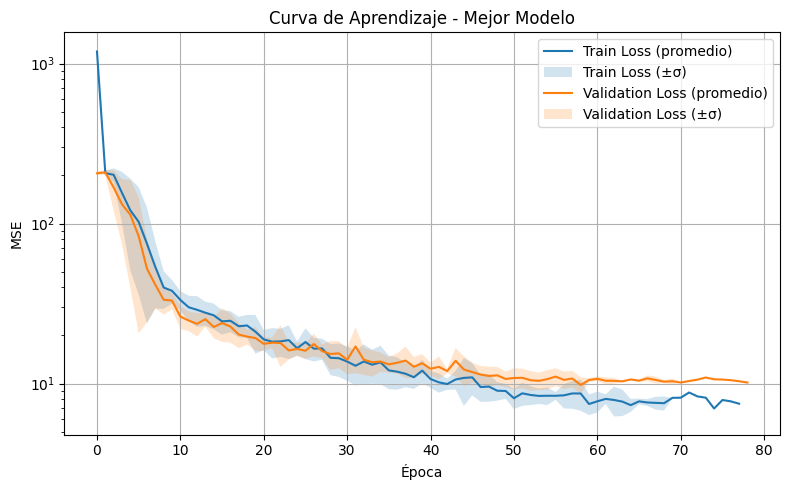

In [6]:
# Graficar curvas de aprendizaje
mean_metrics = get_kfold_mean_metrics(log_directory, best_params, folds)
plot_learning_curves(mean_metrics, 
                    title='Curva de Aprendizaje - Mejor Modelo',
                    save_path='ims/learning_curve_best_model.svg')


### Reentrenar modelo con mejores hiperparámetros

In [7]:
ALL_VIDEOS = [
    ('session1', 'center'),
    ('session1', 'left'),
    ('session1', 'right'),
    ('session2', 'center'),
    ('session2', 'left'),
    ('session2', 'right'),
    ('session3', 'center'),
    ('session3', 'left'),
    ('session3', 'right'),
    ('session4', 'center'),
    ('session4', 'left'),
    ('session4', 'right'),
    ('session5', 'center'),
    ('session5', 'left'),
    ('session5', 'right'),
    ('session6', 'center'),
    ('session6', 'left'),
    ('session6', 'right'),
]

In [8]:
seed = 47
seed_everything(seed)
random.seed(seed)
np.random.seed(seed)

full_list = load_data_list(ALL_VIDEOS, results_folder='../../results_instance', feature_path='all_features')
all_idx = np.arange(len(full_list))
train_val_idx, test_idx = train_test_split(
    all_idx, test_size=0.2, random_state=seed, shuffle=True
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.2, random_state=seed, shuffle=True
)
train_list = [full_list[i] for i in train_idx]
val_list = [full_list[i] for i in val_idx]
test_list = [full_list[i] for i in test_idx]

Seed set to 47


In [ ]:
hparams = best_params
input_size = len(train_list[0]['features'][0])

data_module, model, trainer, logger, result = train_lstm_pipeline(
    # Dataset
    data_list=full_list,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,

    # DataModule params
    batch_size=4,
    split_ratio=(0.64, 0.16, 0.2),
    num_workers=4,

    # LSTM params
    input_size=input_size,
    hidden_size=int(hparams['hidden_size']),
    num_layers=int(hparams['num_layers']),
    output_size=1,
    learning_rate=hparams['lr'],
    dropout=hparams['dropout'],
    weight_decay=hparams['weight_decay'],

    # Logger
    log_path='best_model',

    # Trainer
    patience=7,
    epochs=100,
    log_every_n_steps=10,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA L40S') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


Preparing data for TrackingDataModule...
Setting up TrackingDataModule with 18577 samples.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

   | Name      | Type                       | Params | Mode 
------------------------------------------------------------------
0  | lstm      | LSTM                       | 344 K  | train
1  | dropout   | Dropout                    | 0      | train
2  | fc        | Linear                     | 129    | train
3  | loss_fn   | MSELoss                    | 0      | train
4  | train_mse | MeanSquaredError           | 0      | train
5  | train_mae | MeanAbsoluteError          | 0      | train
6  | train_acc | RelativeRegressionAccuracy | 0      | train
7  | val_mse   | MeanSquaredError           | 0      | train
8  | val_mae   | MeanAbsoluteError          | 0      | train
9  | val_acc   | RelativeRegressionAccuracy | 0      | train
10 | test_mse  | MeanSquaredError           | 0      | train
11 | test_mae  | MeanAbsoluteError          | 0      | train
12 | test_acc  | RelativeRegressionAccuracy | 0      | train
------------------------------------

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (42 outputs left out)

Preparing data for TrackingDataModule...
Setting up TrackingDataModule with 18577 samples.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Validation: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Validate metric      ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_acc          │    0.9787458181381226     │
│         val_loss          │     14.0301513671875      │
│          val_mae          │    1.6396936178207397     │
│          val_mse          │     14.0301513671875      │
└───────────────────────────┴───────────────────────────┘

In [10]:
trainer.test(model, datamodule=data_module)

Preparing data for TrackingDataModule...
Setting up TrackingDataModule with 18577 samples.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.9792448282241821     │
│         test_loss         │    12.243680953979492     │
│         test_mae          │    1.6179168224334717     │
│         test_mse          │    12.243680953979492     │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 12.243680953979492,
  'test_mse': 12.243680953979492,
  'test_mae': 1.6179168224334717,
  'test_acc': 0.9792448282241821}]

In [11]:
predictions = trainer.predict(model, dataloaders=data_module.test_dataloader())
pred_df = pd.DataFrame(predictions, columns=["pred", "target"])

Preparing data for TrackingDataModule...
Setting up TrackingDataModule with 18577 samples.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

In [12]:
df_pred = pd.DataFrame(
    [
        (
            pred[i].item(),
            real[i].item(),
            abs(pred[i].item() - real[i].item())
        )
        for (pred, real) in predictions
        for i in range(len(pred))
    ],
    columns=["Velocidad Predicha", "Velocidad Real", "Error km/h"]
)
df_pred.head(20)

,Velocidad Predicha,Velocidad Real,Error km/h
0,76.399139,76.532402,0.133263
1,63.991325,63.741600,0.249725
2,126.227829,126.986397,0.758568
3,76.216408,76.608002,0.391594
4,78.844200,78.533997,0.310204
5,88.215340,86.666397,1.548943
6,78.090797,76.255203,1.835594
7,72.377701,72.615601,0.237900
8,74.963699,75.171600,0.207901
9,67.646881,67.078796,0.568085


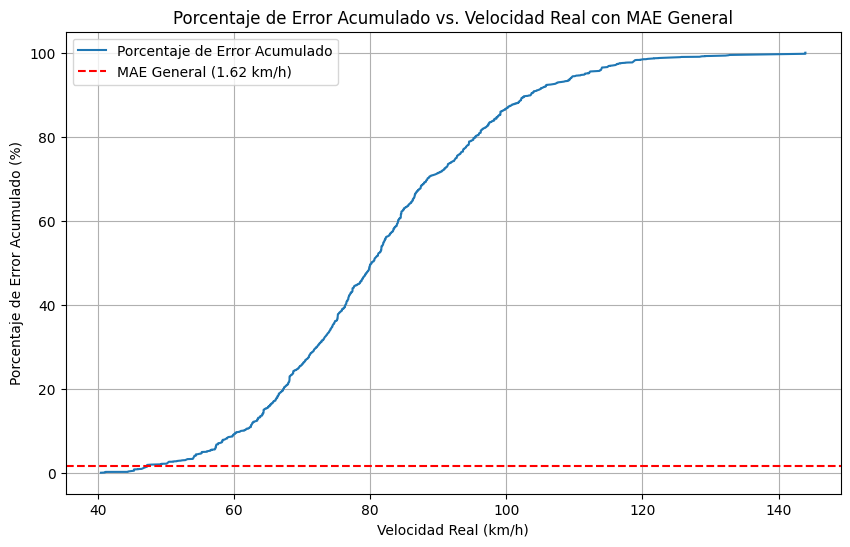

In [13]:
# 1. Gráfica de error acumulado porcentual vs. Velocidad Real con Error Absoluto Medio
df_sorted_speed = df_pred.sort_values('Velocidad Real').reset_index(drop=True)
df_sorted_speed['Error Absoluto'] = abs(df_sorted_speed['Error km/h'])

# Calcular el error acumulado y el porcentaje acumulado
df_sorted_speed['Error Acumulado'] = df_sorted_speed['Error Absoluto'].cumsum()
df_sorted_speed['Porcentaje Error Acumulado'] = (df_sorted_speed['Error Acumulado'] / df_sorted_speed['Error Absoluto'].sum()) * 100

# Calcular el Error Absoluto Medio (MAE) general
mae_general = df_sorted_speed['Error Absoluto'].mean()

plt.figure(figsize=(10, 6))
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Porcentaje Error Acumulado'], label='Porcentaje de Error Acumulado')

# Agregar línea horizontal para el MAE general
plt.axhline(y=mae_general, color='red', linestyle='--', label=f'MAE General ({mae_general:.2f} km/h)')

plt.title('Porcentaje de Error Acumulado vs. Velocidad Real con MAE General')
plt.xlabel('Velocidad Real (km/h)')
plt.ylabel('Porcentaje de Error Acumulado (%)')
plt.legend()
plt.grid(True)
plt.show()


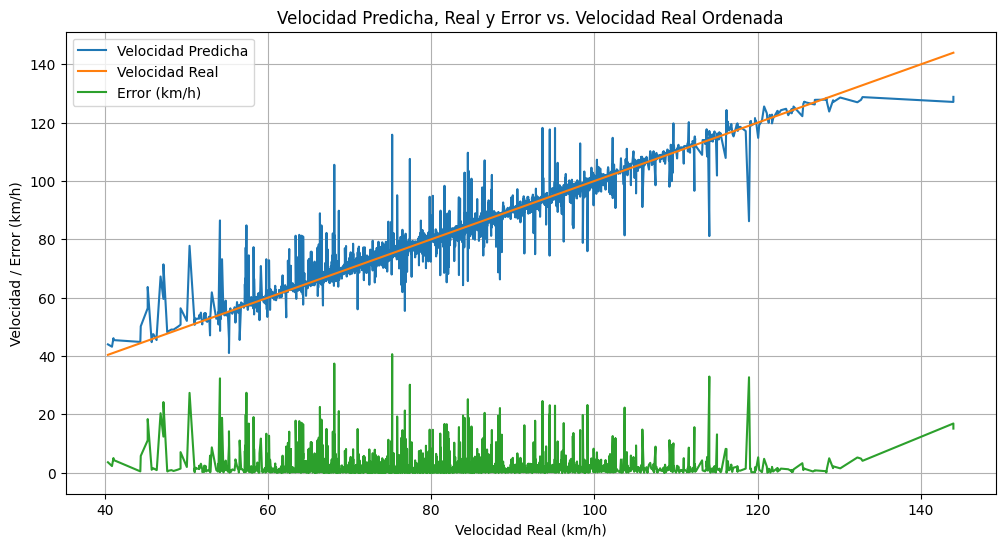

In [14]:
# 2. Gráfica de triple línea (Predicha, Real, Error) vs. Velocidad Real ordenada
df_sorted_speed = df_pred.sort_values('Velocidad Real').reset_index(drop=True)

plt.figure(figsize=(12, 6))
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Velocidad Predicha'], label='Velocidad Predicha')
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Velocidad Real'], label='Velocidad Real')
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Error km/h'], label='Error (km/h)')
plt.title('Velocidad Predicha, Real y Error vs. Velocidad Real Ordenada')
plt.xlabel('Velocidad Real (km/h)')
plt.ylabel('Velocidad / Error (km/h)')
plt.legend()
plt.grid(True)
plt.show()


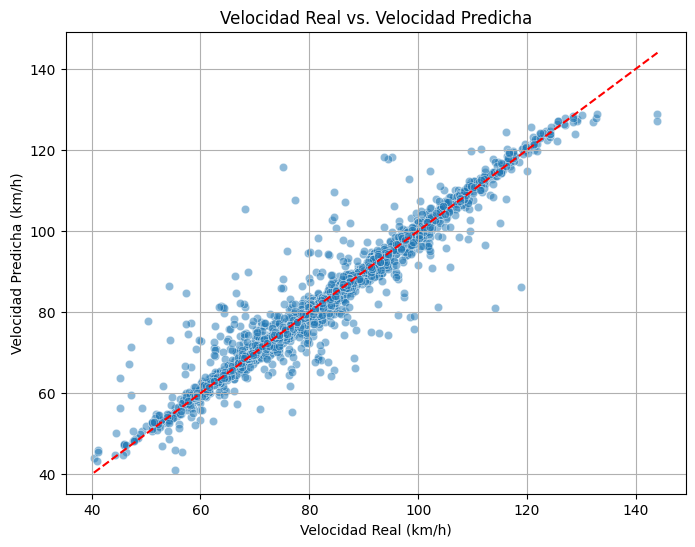

In [15]:
# 3. Gráfico de dispersión de Velocidad Real vs. Velocidad Predicha
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Velocidad Real', y='Velocidad Predicha', data=df_pred, alpha=0.5)
plt.plot([df_pred['Velocidad Real'].min(), df_pred['Velocidad Real'].max()],
         [df_pred['Velocidad Real'].min(), df_pred['Velocidad Real'].max()],
         color='red', linestyle='--')
plt.title('Velocidad Real vs. Velocidad Predicha')
plt.xlabel('Velocidad Real (km/h)')
plt.ylabel('Velocidad Predicha (km/h)')
plt.grid(True)
plt.show()


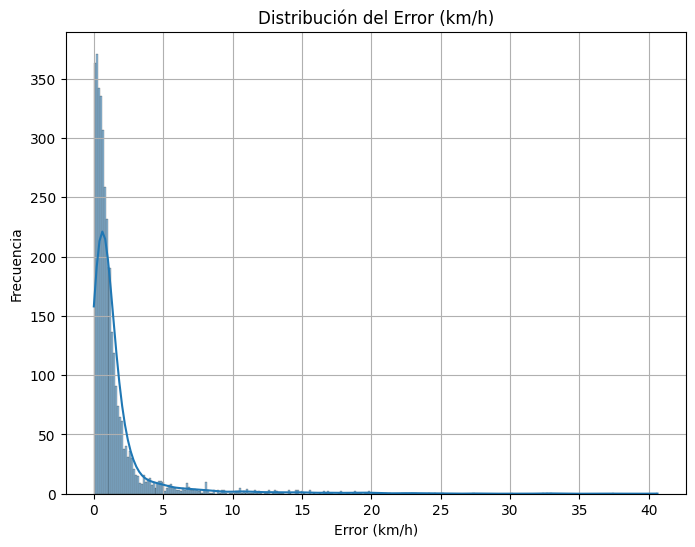

In [16]:
# 4. Histograma del Error
plt.figure(figsize=(8, 6))
sns.histplot(df_pred['Error km/h'], kde=True)
plt.title('Distribución del Error (km/h)')
plt.xlabel('Error (km/h)')
plt.ylabel('Frecuencia')
plt.grid(True)
plt.show()


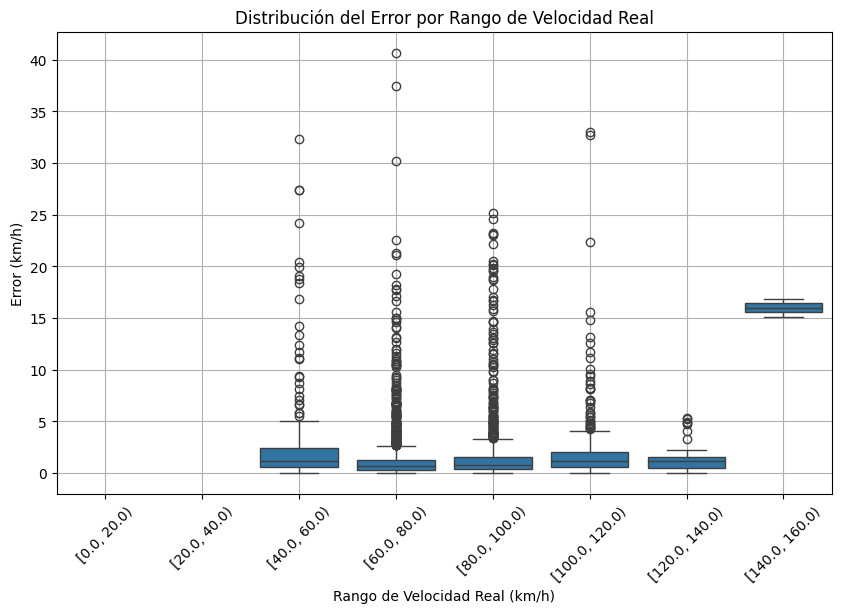

In [17]:
# 5. Gráfico de caja del Error por rangos de Velocidad Real
# Define los rangos de velocidad
bins = np.arange(0, df_pred['Velocidad Real'].max() + 20, 20)
df_pred['Rango Velocidad Real'] = pd.cut(df_pred['Velocidad Real'], bins=bins, right=False)

plt.figure(figsize=(10, 6))
sns.boxplot(x='Rango Velocidad Real', y='Error km/h', data=df_pred)
plt.title('Distribución del Error por Rango de Velocidad Real')
plt.xlabel('Rango de Velocidad Real (km/h)')
plt.ylabel('Error (km/h)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


/tmp/ipykernel_4154694/3845453519.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mae_por_rango = df_pred.groupby('Rango Velocidad Real')['Error km/h'].mean().reset_index()


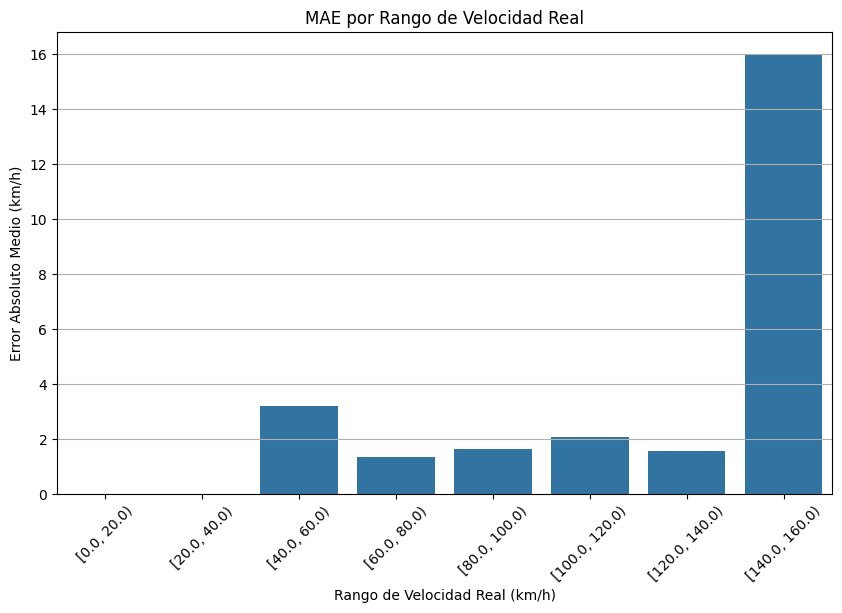

In [18]:
# 6. Gráfico de error absoluto medio (MAE) por rangos de Velocidad Real
mae_por_rango = df_pred.groupby('Rango Velocidad Real')['Error km/h'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(x='Rango Velocidad Real', y='Error km/h', data=mae_por_rango)
plt.title('MAE por Rango de Velocidad Real')
plt.xlabel('Rango de Velocidad Real (km/h)')
plt.ylabel('Error Absoluto Medio (km/h)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()


<Figure size 1200x600 with 0 Axes>

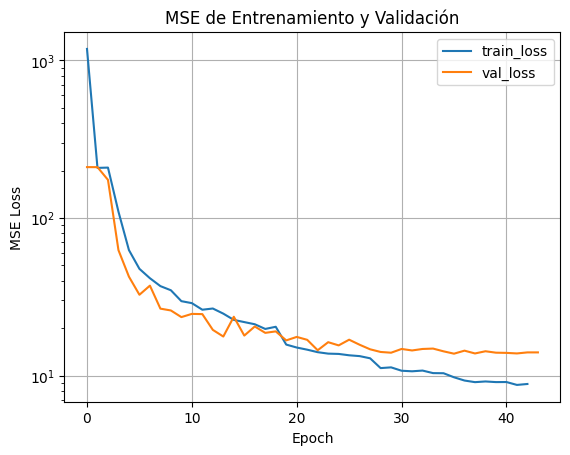

In [19]:
metrics = pd.read_csv(f"{trainer.logger.log_dir}/metrics.csv")

aggreg_metrics = []
agg_col = "epoch"
for i, dfg in metrics.groupby(agg_col):
    agg = dict(dfg.mean())
    agg[agg_col] = i
    aggreg_metrics.append(agg)

df_metrics = pd.DataFrame(aggreg_metrics)

plt.figure(figsize=(12, 6)) 
ax = df_metrics[["train_loss", "val_loss"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch",
    ylabel="MSE Loss", 
    title="MSE de Entrenamiento y Validación", 
)
ax.set_yscale('log')



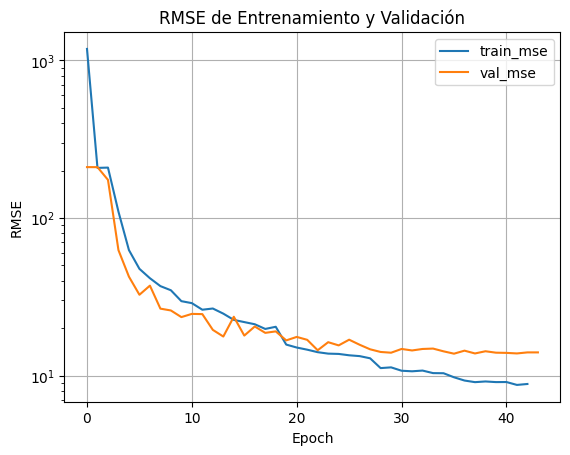

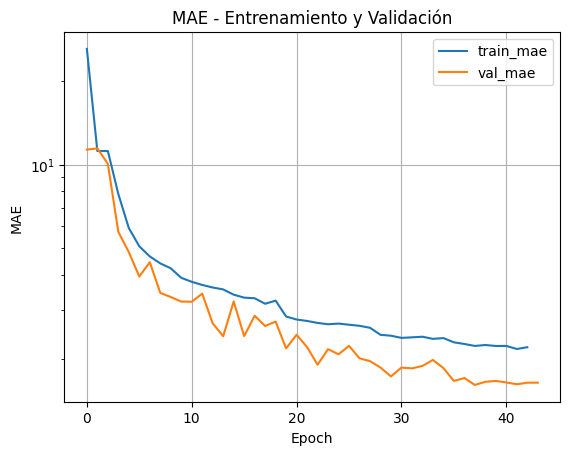

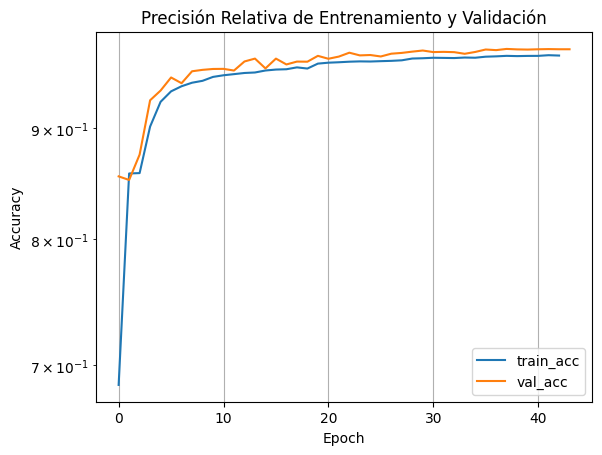

In [20]:
ax = df_metrics[["train_mse", "val_mse"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="RMSE",
    title="RMSE de Entrenamiento y Validación",
)
ax.set_yscale('log')

ax = df_metrics[["train_mae", "val_mae"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="MAE",
    title="MAE - Entrenamiento y Validación",
)
ax.set_yscale('log')

ax = df_metrics[["train_acc", "val_acc"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="Accuracy",
    title="Precisión Relativa de Entrenamiento y Validación",
)
ax.set_yscale('log')